In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn import preprocessing, cluster, decomposition

In [6]:
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
df.head()
df.shape

(2823, 25)

In [8]:
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
X = df[features]

In [9]:
scaler = preprocessing.StandardScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)

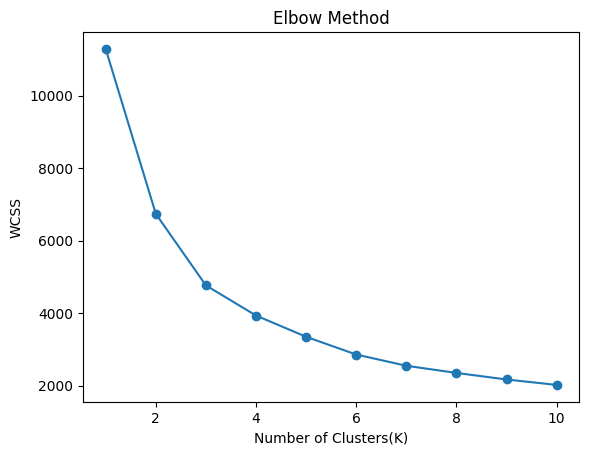

In [10]:
wcss = []
for k in range(1,11):
    km = cluster.KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1,11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters(K)")
plt.ylabel("WCSS")
plt.show()

In [11]:
km = cluster.KMeans(n_clusters=3, random_state=42, n_init=10)
km.fit(X_scaled)
df['Cluster'] = km.predict(X_scaled)

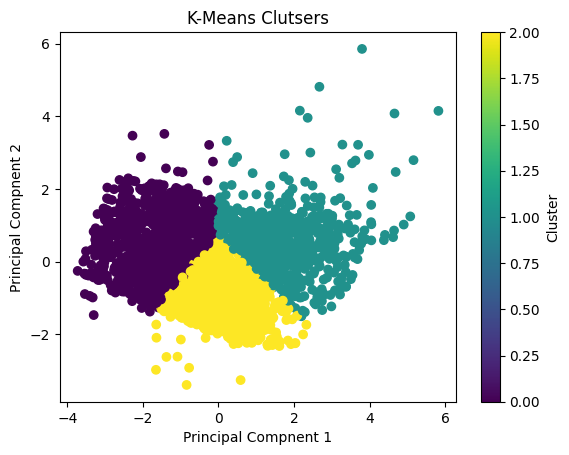

In [14]:
pca = decomposition.PCA(2)
pca = pca.fit_transform(X_scaled)

plt.scatter(pca[:,0], pca[:,1], c=df['Cluster'])
plt.title("K-Means Clutsers")
plt.xlabel("Principal Compnent 1")
plt.ylabel("Principal Compnent 2")
plt.colorbar(label="Cluster")
plt.show()